# Lesson 1: The data, and the transforms by hand

An **emulator** is a function, fitted to examples, that returns what an expensive code would return for the same inputs. Ours maps six numbers describing a parcel of gas (temperature, pressure, metallicity and three element ratios) to 19 numbers (18 log10 mixing ratios and the mean molecular weight), trained on 250,000 FastChem models.

Everything in this course is linear algebra on two matrices: the inputs **X**, one row per model and one column per input, and the outputs **Y**, one row per model and one column per output. Each section shows three things:

- **the maths**, with the shape of every array
- **the code**, written out in NumPy instead of hidden in a function
- **a check**, usually that the hand-written version gives exactly what the `emulator` package gives, so that later lessons can call the package with confidence.

This lesson reads the grid by hand, looks at it, splits it, and builds the two transforms the network needs.

In [1]:
# 1. Let Python find the emulator package (one folder up from lessons/)
import sys

sys.path.insert(0, "..")

# 2. Imports
import json

import h5py
import matplotlib.pyplot as plt
import numpy as np

from emulator import data
from emulator.evaluate import PALETTE

GRID_FILE = "../training_250k.h5"

## 1. The training set as two matrices

With N = 250,000 models, D = 6 inputs and K = 19 outputs:

$$ X \in \mathbb{R}^{N \times D}, \qquad Y \in \mathbb{R}^{N \times K} $$

Row *i* of X holds the inputs of model *i* and row *i* of Y its outputs. An HDF5 file is a container of named arrays ("datasets"), and `h5py` reads each one into a NumPy array.

In [2]:
# 1. Open the file and see what it holds
with h5py.File(GRID_FILE, "r") as file:
    print(len(file.keys()), "datasets, for example:", list(file.keys())[:8])

    # 2. Read the inputs, the outputs and the split labels
    X = file["features"][:]  # (N, 6)
    log10_vmr = file["log10_vmr"][:].astype(np.float64)  # (N, 18)
    log10_mu = file["log10_mean_molecular_weight"][:].astype(np.float64)  # (N,)
    split = file["split"][:]  # (N,)
    input_names = [name.decode() for name in file["feature_names"][:]]
    species = [name.decode() for name in file["species_labels"][:]]
    config = json.loads(file.attrs["config_json"])

# 3. The 18 species and the mean molecular weight side by side
Y = np.column_stack([log10_vmr, log10_mu])  # (N, 19)
output_names = species + ["mu"]

print("X:", X.shape, input_names)
print("Y:", Y.shape, output_names)

35 datasets, for example: ['attempts', 'chemistry_iterations', 'condensate_number_densities', 'condensate_symbols', 'condensation_iterations', 'element_abundances', 'element_condensation_degree', 'element_conserved']
X: (250000, 6) ['log10_T_K', 'log10_P_bar', 'MH_dex', 'log10_C_O', 'log10_S_O', 'log10_N_O']
Y: (250000, 19) ['H', 'H2', 'H-', 'e-', 'He', 'H2O', 'CO', 'CO2', 'CH4', 'C2H2', 'Fe', 'TiO', 'SiO', 'HCN', 'NH3', 'N2', 'H2S', 'OH', 'mu']


**Check** that `data.load_grid` in the package does exactly these reads:

In [3]:
grid = data.load_grid(GRID_FILE)
print("same X:", np.array_equal(grid["inputs"], X))
print("same Y:", np.array_equal(grid["outputs"], Y))

same X: True
same Y: True


The generator's settings travel with the file as a JSON string:

In [4]:
for key in ["sampling", "condensation", "rainout", "vmr_floor", "metal_budget"]:
    print(f"{key:13s} {config[key]}")

sampling      Latin hypercube uniform in log10 features
condensation  True
rainout       False
vmr_floor     1e-30
metal_budget  C+N+O+S number per H; other metals scale as 10**MH; fixed H/He


The features are already logarithms (log10 T [K], log10 P [bar], [M/H] [dex], log10 C/O, log10 S/O and log10 N/O), condensation is on and rainout off, and the outputs are floored at 10⁻³⁰. The file's `species_names` calls both H and H2 "Hydrogen", which is why we read `species_labels`.

## 2. The inputs

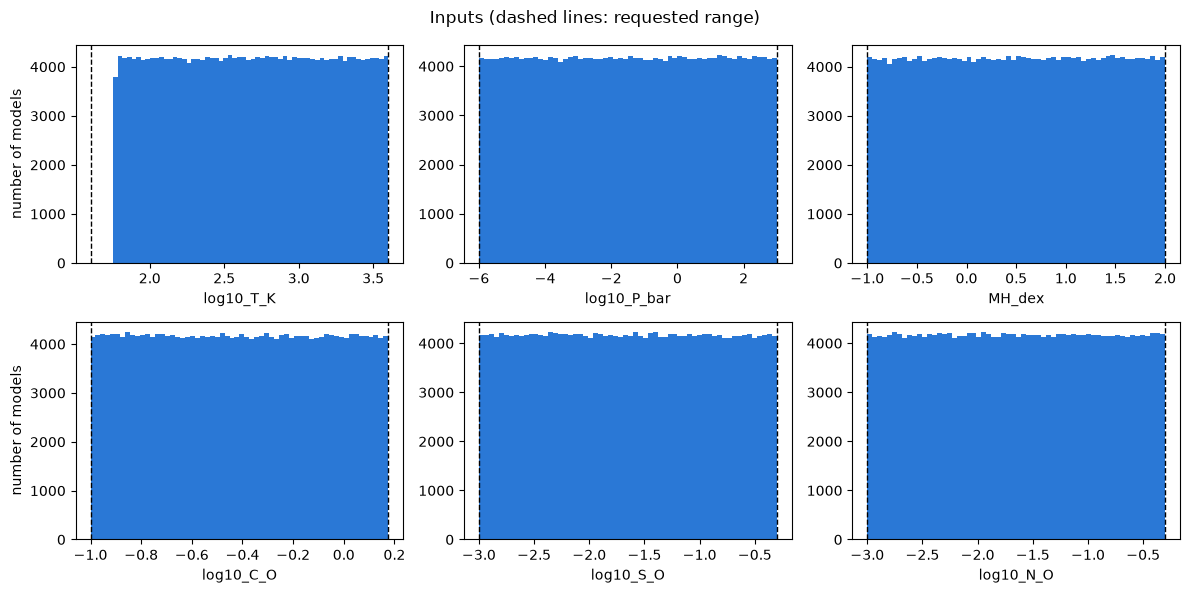

In [5]:
# 1. One histogram per input, with the requested range as dashed lines
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for column, ax in enumerate(axes.ravel()):
    ax.hist(X[:, column], bins=60, color=PALETTE[0])
    for bound in config["feature_bounds"][column]:
        ax.axvline(bound, color="black", ls="--", lw=1)
    ax.set_xlabel(input_names[column])

# 2. Labels
for ax in axes[:, 0]:
    ax.set_ylabel("number of models")
fig.suptitle("Inputs (dashed lines: requested range)")
fig.tight_layout()
plt.show()

The histograms are flat because a **Latin hypercube** spreads the models evenly along every axis, giving each model its own value of every input. The temperature histogram stops at 57 K instead of the requested 40 K because FastChem failed for every attempt below that, so the emulator is only valid above about 60 K.

How densely do 250,000 models cover six dimensions? A regular grid with the same number of points would have N^(1/D) points per axis, with a spacing of (range)/N^(1/D):

In [6]:
# 1. Points per axis and spacing of an equivalent regular grid
n_models, n_inputs = X.shape
points_per_axis = n_models ** (1 / n_inputs)
print(f"N^(1/D) = {n_models}^(1/{n_inputs}) = {points_per_axis:.1f} points per axis")
for name, width in zip(input_names, X.max(axis=0) - X.min(axis=0)):
    print(f"  spacing in {name:10s}: {width / points_per_axis:.2f}")

N^(1/D) = 250000^(1/6) = 7.9 points per axis
  spacing in log10_T_K : 0.23
  spacing in log10_P_bar: 1.13
  spacing in MH_dex    : 0.38
  spacing in log10_C_O : 0.15
  spacing in log10_S_O : 0.34
  spacing in log10_N_O : 0.34


This is the **curse of dimensionality**: neighbouring models sit 0.23 dex apart in temperature and more than a dex apart in pressure, so anything that changes faster than that, like a condensation cliff, is seen by only a few models. Filling these gaps sensibly is the emulator's job.

## 3. The outputs

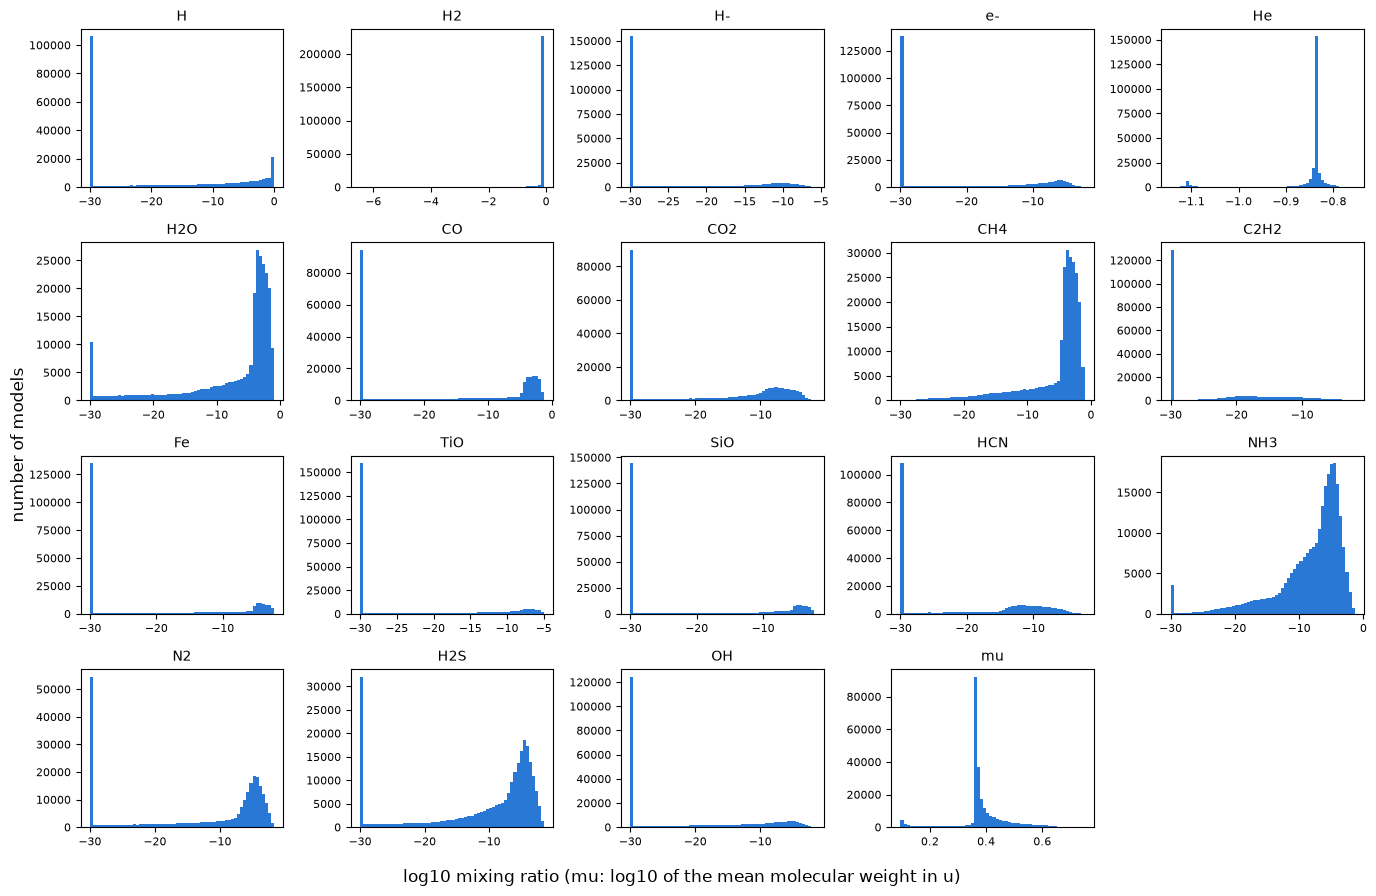

In [7]:
# 1. One histogram per output
fig, axes = plt.subplots(4, 5, figsize=(14, 9))
axes = axes.ravel()
for column, name in enumerate(output_names):
    axes[column].hist(Y[:, column], bins=60, color=PALETTE[0])
    axes[column].set_title(name, fontsize=10)
    axes[column].tick_params(labelsize=8)

# 2. Hide the empty panel and label the axes once
axes[-1].set_visible(False)
fig.supxlabel("log10 mixing ratio (mu: log10 of the mean molecular weight in u)")
fig.supylabel("number of models")
fig.tight_layout()
plt.show()

In [8]:
# 1. Fraction of models at the floor, species by species (mu has no floor)
at_floor = np.mean(Y[:, :-1] <= -29.999, axis=0)
for name, fraction in zip(output_names[:-1], at_floor):
    print(f"{name:5s} {100 * fraction:5.1f}% at the floor")

H      42.1% at the floor
H2      0.0% at the floor
H-     61.6% at the floor
e-     55.0% at the floor
He      0.0% at the floor
H2O     3.9% at the floor
CO     37.4% at the floor
CO2    35.7% at the floor
CH4     0.0% at the floor
C2H2   51.3% at the floor
Fe     53.8% at the floor
TiO    63.6% at the floor
SiO    57.6% at the floor
HCN    43.0% at the floor
NH3     1.4% at the floor
N2     21.6% at the floor
H2S    12.6% at the floor
OH     49.5% at the floor


Nine species sit on the floor in 40% to 64% of the models. The network must output exactly the floor over large regions and climb steeply off it elsewhere, and a function built from smooth pieces finds sharp corners hard.

## 4. The chemistry in the data

4260 models near solar composition


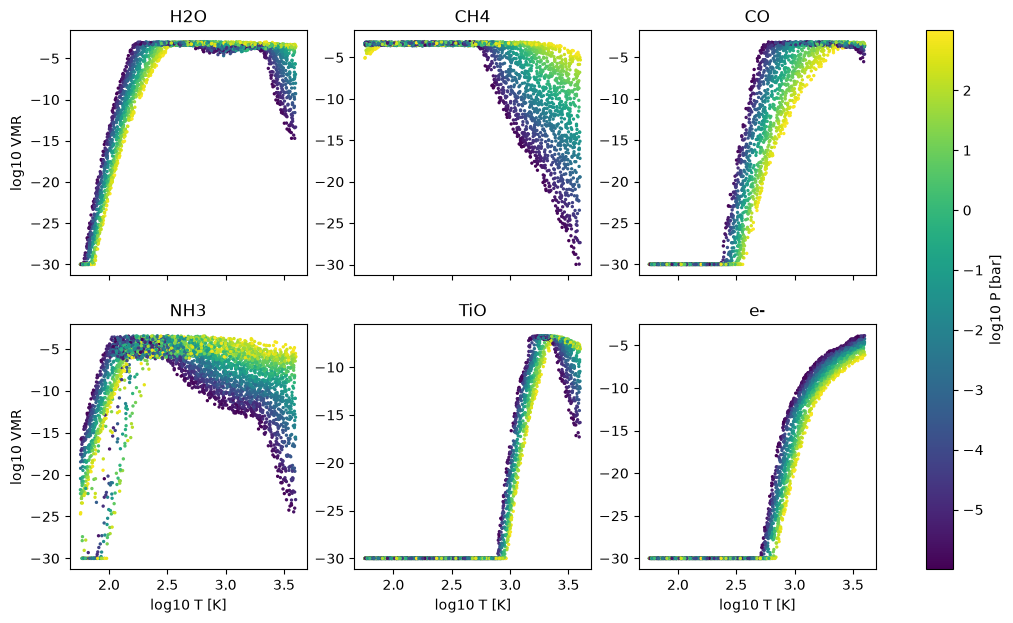

In [9]:
# 1. Models near [M/H] = 0 and C/O = 0.55 (solar C/O, Asplund et al. 2009)
near_solar = (np.abs(X[:, 2]) < 0.15) & (np.abs(X[:, 3] - np.log10(0.55)) < 0.1)
print(f"{near_solar.sum()} models near solar composition")

# 2. Six species against temperature, coloured by pressure
species_to_plot = ["H2O", "CH4", "CO", "NH3", "TiO", "e-"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, name in zip(axes.ravel(), species_to_plot):
    column = output_names.index(name)
    points = ax.scatter(
        X[near_solar, 0],
        Y[near_solar, column],
        c=X[near_solar, 1],
        s=2,
        cmap="viridis",
        rasterized=True,
    )
    ax.set_title(name)

# 3. Shared labels and colour bar
for ax in axes[:, 0]:
    ax.set_ylabel("log10 VMR")
for ax in axes[1]:
    ax.set_xlabel("log10 T [K]")
fig.colorbar(points, ax=axes, label="log10 P [bar]")
plt.show()

CH4 carries the carbon at low temperature and high pressure and CO at high temperature and low pressure, with the switch moving with pressure. H2O falls away where water condenses at the coldest temperatures, and again at the hottest temperatures and lowest pressures, where it breaks apart. TiO drops off a cliff onto the floor where titanium-bearing condensates form, NH3 condenses at the lowest temperatures and gives way to N2 as the temperature rises, and free electrons appear only at high temperature.

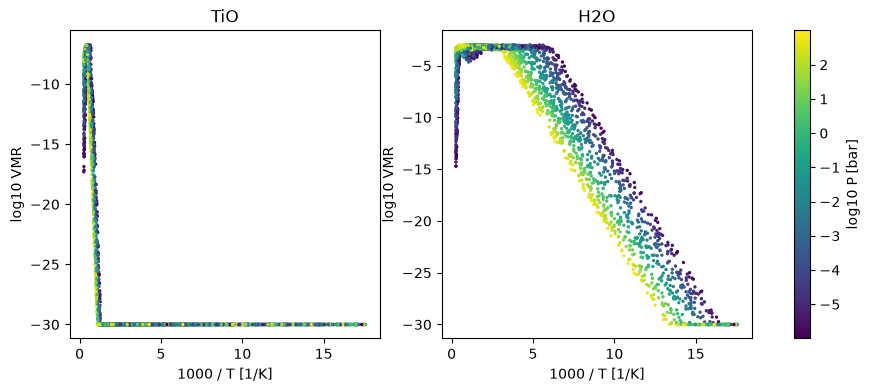

In [10]:
# 1. Two species against 1000 / T
inverse_temperature = 1000.0 / 10.0 ** X[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["TiO", "H2O"]):
    column = output_names.index(name)
    points = ax.scatter(
        inverse_temperature[near_solar],
        Y[near_solar, column],
        c=X[near_solar, 1],
        s=2,
        cmap="viridis",
        rasterized=True,
    )
    ax.set(title=name, xlabel="1000 / T [1/K]", ylabel="log10 VMR")
fig.colorbar(points, ax=axes, label="log10 P [bar]")
plt.show()

Below a condensation point the gas holds what the vapour pressure allows, and vapour pressures go as exp(−E/kT), so log10 VMR falls along a straight line in 1/T (the H2O panel). The TiO panel shows the catch: the grid is uniform in log T, so everything hotter than about 800 K is squeezed into the left tenth of the axis. Lesson 4 tests which input works better.

## 5. Splitting is indexing

The training, validation and test sets are three disjoint sets of row numbers, and selecting a set is indexing: `X[train]` is the submatrix of the training rows. The file assigns every model to one set, so everyone in the team tests on the same models.

In [11]:
# 1. Row numbers of each set
train = np.flatnonzero(split == 0)
val = np.flatnonzero(split == 1)
test = np.flatnonzero(split == 2)
print(f"train {len(train)}, validation {len(val)}, test {len(test)}")

# 2. Every row is in exactly one set
print(
    "disjoint and complete:", len(np.union1d(np.union1d(train, val), test)) == n_models
)

train 200000, validation 25000, test 25000
disjoint and complete: True


- **Training set**: fits the weights.
- **Validation set**: guides every choice (network size, learning rate, when to stop), so its error is slightly optimistic.
- **Test set**: looked at once, at the end, to report the final error.

## 6. The input transform, by hand

For each input column *j*, the training rows give a minimum and a maximum,

$$ l_j = \min_{i \in \text{train}} X_{ij}, \qquad u_j = \max_{i \in \text{train}} X_{ij}, $$

and every model is mapped onto [−1, 1] with

$$ X'_{ij} = \frac{2\,(X_{ij} - l_j)}{u_j - l_j} - 1 . $$

This is an affine map applied column by column. In matrix form it is $X' = X D + \mathbb{1} c^{\mathsf T}$, with $D = \mathrm{diag}(d)$, $d_j = 2/(u_j - l_j)$ and $c_j = -(u_j + l_j)/(u_j - l_j)$, where $\mathbb{1}$ is a column of N ones. In NumPy, subtracting a (6,) vector from an (N, 6) array subtracts it from every row ("broadcasting"), which is the $\mathbb{1} c^{\mathsf T}$ term.

In [12]:
# 1. The constants, from the training rows only
lower = X[train].min(axis=0)  # l, shape (6,)
upper = X[train].max(axis=0)  # u, shape (6,)

# 2. The map, applied to every model
X_scaled = 2.0 * (X - lower) / (upper - lower) - 1.0  # (N, 6)

# 3. The same map written as a matrix product, X' = X D + 1 c^T
d = 2.0 / (upper - lower)
c = -(upper + lower) / (upper - lower)
X_scaled_matrix = X @ np.diag(d) + c
print(
    "largest difference between the two forms:",
    np.abs(X_scaled - X_scaled_matrix).max(),
)
print("training rows after scaling, min:", X_scaled[train].min(axis=0).round(6))
print("training rows after scaling, max:", X_scaled[train].max(axis=0).round(6))

largest difference between the two forms: 8.881784197001252e-16
training rows after scaling, min: [-1. -1. -1. -1. -1. -1.]
training rows after scaling, max: [1. 1. 1. 1. 1. 1.]


**Check** against the package:

In [13]:
input_transform = data.fit_input_transform(X[train])
print(
    "same l and u:",
    np.array_equal(input_transform["lower"], lower),
    np.array_equal(input_transform["upper"], upper),
)
print(
    "largest difference:",
    np.abs(data.transform_inputs(X, input_transform) - X_scaled).max(),
)

same l and u: True True
largest difference: 0.0


Scaling matters because the first layer of a network forms weighted sums of the inputs, starting from random weights of similar size, so an input spanning nine units would otherwise drown one spanning one unit. After scaling, any value outside [−1, 1] also flags a point outside the training range.

## 7. The output transform, by hand

First a floor F, applied element by element, then each column is standardized with the mean and standard deviation of the training rows:

$$ \tilde Y_{ik} = \max(Y_{ik}, F), \qquad \mu_k = \frac{1}{N_{\text{train}}} \sum_{i \in \text{train}} \tilde Y_{ik}, \qquad \sigma_k^2 = \frac{1}{N_{\text{train}}} \sum_{i \in \text{train}} (\tilde Y_{ik} - \mu_k)^2 , $$

$$ Y'_{ik} = \frac{\tilde Y_{ik} - \mu_k}{\sigma_k}, \qquad \text{and back:} \quad Y_{ik} = \max(\sigma_k Y'_{ik} + \mu_k,\; F) . $$

Here we use the grid's own floor, F = −30, so the max changes nothing yet. Lesson 4 shows that raising it to −15 helps the network.

In [14]:
FLOOR = -30.0

# 1. Floor, then the mean and spread of each column over the training rows
Y_floored = np.maximum(Y, FLOOR)  # (N, 19)
mean = Y_floored[train].mean(axis=0)  # mu, shape (19,)
std = Y_floored[train].std(axis=0)  # sigma, shape (19,)

# 2. Standardize every model
Y_scaled = (Y_floored - mean) / std  # (N, 19)

# 3. Undo it and compare
Y_back = np.maximum(Y_scaled * std + mean, FLOOR)
print("largest round-trip difference:", np.abs(Y_back - Y_floored).max(), "dex")
print(
    "training columns now have mean",
    np.abs(Y_scaled[train].mean(axis=0)).max().round(12),
    "and std",
    Y_scaled[train].std(axis=0).min().round(12),
    "to",
    Y_scaled[train].std(axis=0).max().round(12),
)

largest round-trip difference: 7.105427357601002e-15 dex


training columns now have mean 0.0 and std 0.999999999998 to 1.000000000002


**Check** against the package:

In [15]:
output_transform = data.fit_output_transform(Y[train], log10_floor=FLOOR)
print(
    "same mu and sigma:",
    np.array_equal(output_transform["mean"], mean),
    np.array_equal(output_transform["std"], std),
)
print(
    "largest difference:",
    np.abs(data.transform_outputs(Y, output_transform) - Y_scaled).max(),
)

same mu and sigma: True True
largest difference: 0.0


The constants the output transform stores:

In [16]:
for name, m, s in zip(output_names, mean, std):
    print(f"{name:5s} mu {m:7.2f}   sigma {s:6.2f}   [dex]")

H     mu  -17.85   sigma  12.19   [dex]
H2    mu   -0.24   sigma   0.70   [dex]
H-    mu  -24.03   sigma   8.42   [dex]
e-    mu  -21.70   sigma  10.32   [dex]
He    mu   -0.86   sigma   0.07   [dex]
H2O   mu   -7.55   sigma   7.87   [dex]
CO    mu  -16.20   sigma  12.23   [dex]
CO2   mu  -17.72   sigma  10.55   [dex]
CH4   mu   -5.63   sigma   5.16   [dex]
C2H2  mu  -23.02   sigma   8.32   [dex]
Fe    mu  -20.67   sigma  11.31   [dex]
TiO   mu  -23.63   sigma   9.30   [dex]
SiO   mu  -21.33   sigma  11.18   [dex]
HCN   mu  -20.15   sigma   9.65   [dex]
NH3   mu   -8.28   sigma   5.37   [dex]
N2    mu  -13.13   sigma  10.60   [dex]
H2S   mu  -11.05   sigma   9.16   [dex]
OH    mu  -21.07   sigma  10.26   [dex]
mu    mu    0.39   sigma   0.09   [dex]


Standardizing puts the 19 columns on an equal footing in the loss, which adds up squared errors over all of them. Without it, TiO (spread 9.3 dex) would dominate and the mean molecular weight (spread 0.09 dex) would be ignored. The cost is that the network is asked to be equally good relative to each column's spread: an error of 0.01 in standardized units is 0.09 dex for TiO but 0.0009 dex for `mu`.

Both transforms are fitted on the training rows only. Using the validation or test rows would leak information about them into the emulator, and the errors measured on them would come out optimistic.

## 8. Everything this lesson built

| Array | Shape | What it is |
|---|---|---|
| `X`, `X_scaled` | (250000, 6) | inputs, raw and scaled to [−1, 1] |
| `Y`, `Y_scaled` | (250000, 19) | log10 outputs, raw and standardized |
| `lower`, `upper` | (6,) | l and u, the input range of the training rows |
| `mean`, `std` | (19,) | μ and σ, the output statistics of the training rows |
| `train`, `val`, `test` | (200000,), (25000,), (25000,) | row numbers of each set |

From Lesson 2 on we call `data.load_grid`, `data.fit_input_transform` and `data.fit_output_transform`, knowing that they do exactly what we just wrote.

## Exercises

1. Plot H2S and HCN against temperature for the near-solar slice. Where does each one reach the floor?
2. Write the inverse of the input transform (from X' back to X) and check it on the test rows.
3. Recompute `mean` and `std` using all 250,000 models instead of the training rows. How large are the differences, and why would they matter for an honest test?
4. What fraction of the training models are colder than 100 K, and is that enough to learn the NH3 cliff?